In [4]:
# 1. Imports and configuration
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, f1_score
)

RANDOM_STATE = 42
TARGET = "Condition_Class"
CLASS_NAMES = ["Excellent", "Good", "Fair", "Poor"]


In [5]:
# 2. Load the existing dataset splits
# Edit these paths only if your CSV files are stored elsewhere.
TRAIN_PATH = "../training_image_features.csv"
VALID_PATH = "../validation_image_features.csv"
TEST_PATH  = "../testing_image_features.csv"

train_df = pd.read_csv(TRAIN_PATH)
valid_df = pd.read_csv(VALID_PATH)
test_df  = pd.read_csv(TEST_PATH)

for name, df in [("Training", train_df), ("Validation", valid_df), ("Testing", test_df)]:
    print(f"{name}: {df.shape}")
    print(df[TARGET].value_counts().reindex(CLASS_NAMES, fill_value=0))
    print()


Training: (10058, 43)
Condition_Class
Excellent     100
Good         2176
Fair         6907
Poor          875
Name: count, dtype: int64

Validation: (3237, 43)
Condition_Class
Excellent      40
Good          722
Fair         2183
Poor          292
Name: count, dtype: int64

Testing: (3224, 43)
Condition_Class
Excellent      41
Good          716
Fair         2193
Poor          274
Name: count, dtype: int64



In [6]:
LEAKAGE_OR_ID_COLUMNS = [
    "Condition_Class", "Condition_Score", "Damage_Score",
    "Structural_Integrity", "Recovery_Pathway",
    "Reconditioning_Required", "Recovery_Potential",
    "Alternative_Use_Category", "Alternative_Use_Suitability",
    "Sample_ID", "Image_ID"
]

feature_columns = [col for col in train_df.columns if col not in LEAKAGE_OR_ID_COLUMNS]
X_train, y_train = train_df[feature_columns].copy(), train_df[TARGET].astype(str)
X_valid, y_valid = valid_df[feature_columns].copy(), valid_df[TARGET].astype(str)
X_test, y_test = test_df[feature_columns].copy(), test_df[TARGET].astype(str)

# Use the training schema to identify column types.
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [c for c in feature_columns if c not in numeric_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ],
    remainder="drop"
)

print("Number of input features:", len(feature_columns))
print("Numeric columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))
print("Selected features:", feature_columns)


Number of input features: 32
Numeric columns: 26
Categorical columns: 6
Selected features: ['Material_Type', 'Material_Subtype', 'Source', 'Exposure_Type', 'Crack_Level', 'Surface_Damage', 'Breakage_Level', 'Discoloration_Level', 'Deformation_Level', 'Missing_Portion', 'pixel_img_width', 'pixel_img_height', 'pixel_obj_width', 'pixel_obj_height', 'relative_area', 'edge_density', 'fill_ratio', 'color_std', 'mean_brightness', 'std_brightness', 'contrast', 'texture_laplacian_var', 'dark_pixel_ratio', 'bright_pixel_ratio', 'mean_hue', 'mean_saturation', 'saturation_std', 'contour_area', 'contour_perimeter', 'circularity', 'solidity', 'extent']


In [7]:
def evaluate_model(model, X, y, model_name, split_name):
    predictions = model.predict(X)
    print(f"\n{model_name} – {split_name}")
    print("Accuracy:", round(accuracy_score(y, predictions), 4))
    print("Macro F1:", round(f1_score(y, predictions, average="macro", zero_division=0), 4))
    print("Weighted F1:", round(f1_score(y, predictions, average="weighted", zero_division=0), 4))
    print("\nClassification report:")
    print(classification_report(y, predictions, labels=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(y, predictions, labels=CLASS_NAMES)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(cmap="Blues", values_format="d", xticks_rotation=30)
    plt.title(f"{model_name} – {split_name} confusion matrix")
    plt.tight_layout()
    plt.show()
    return {
        "Model": model_name, "Split": split_name,
        "Accuracy": accuracy_score(y, predictions),
        "Macro F1": f1_score(y, predictions, average="macro", zero_division=0),
        "Weighted F1": f1_score(y, predictions, average="weighted", zero_division=0)
    }



Random Forest – Validation
Accuracy: 0.9765
Macro F1: 0.9588
Weighted F1: 0.9762

Classification report:
              precision    recall  f1-score   support

   Excellent       1.00      0.90      0.95        40
        Good       0.99      0.96      0.97       722
        Fair       0.97      1.00      0.98      2183
        Poor       1.00      0.87      0.93       292

    accuracy                           0.98      3237
   macro avg       0.99      0.93      0.96      3237
weighted avg       0.98      0.98      0.98      3237



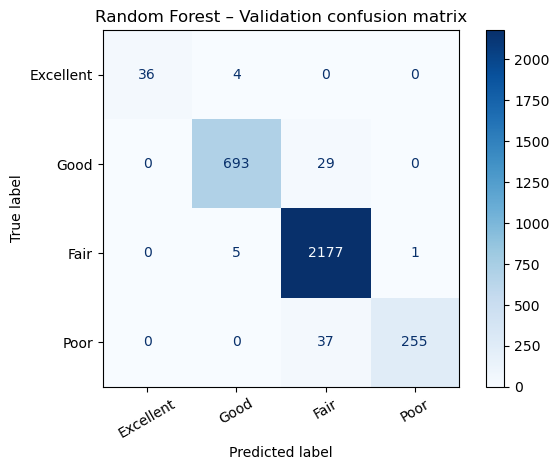

In [8]:
random_forest = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=1,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

random_forest.fit(X_train, y_train)
rf_valid_result = evaluate_model(random_forest, X_valid, y_valid, "Random Forest", "Validation")


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(



AdaBoost – Validation
Accuracy: 0.8854
Macro F1: 0.8536
Weighted F1: 0.8823

Classification report:
              precision    recall  f1-score   support

   Excellent       1.00      0.90      0.95        40
        Good       0.79      0.92      0.85       722
        Fair       0.91      0.92      0.92      2183
        Poor       1.00      0.54      0.70       292

    accuracy                           0.89      3237
   macro avg       0.93      0.82      0.85      3237
weighted avg       0.89      0.89      0.88      3237



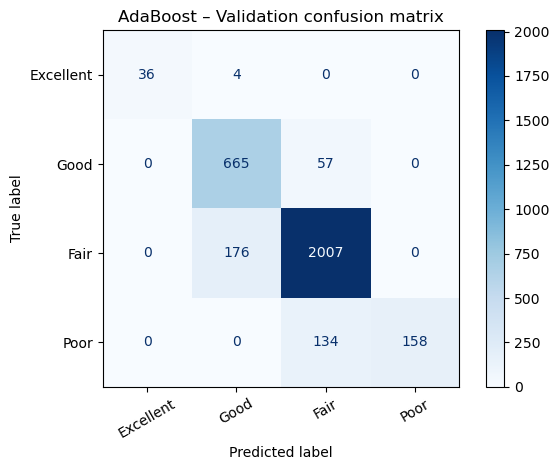

In [9]:
ada_boost = Pipeline([
    ("preprocess", preprocessor),
    ("model", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
        n_estimators=150,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    ))
])

ada_sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
ada_boost.fit(X_train, y_train, model__sample_weight=ada_sample_weights)
ada_valid_result = evaluate_model(ada_boost, X_valid, y_valid, "AdaBoost", "Validation")


In [10]:
validation_results = pd.DataFrame([rf_valid_result, ada_valid_result])
validation_results.sort_values("Macro F1", ascending=False).reset_index(drop=True)


,Model,Split,Accuracy,Macro F1,Weighted F1
0,Random Forest,Validation,0.976521,0.958768,0.976172
1,AdaBoost,Validation,0.885388,0.853644,0.882259



Random Forest – Test
Accuracy: 0.9848
Macro F1: 0.9658
Weighted F1: 0.9846

Classification report:
              precision    recall  f1-score   support

   Excellent       1.00      0.88      0.94        41
        Good       0.99      0.97      0.98       716
        Fair       0.98      1.00      0.99      2193
        Poor       1.00      0.92      0.96       274

    accuracy                           0.98      3224
   macro avg       0.99      0.94      0.97      3224
weighted avg       0.98      0.98      0.98      3224



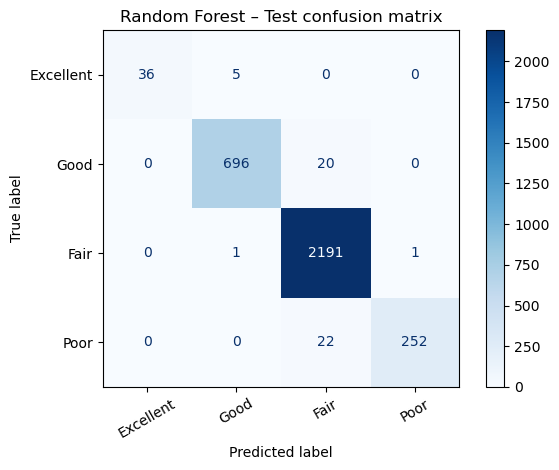


AdaBoost – Test
Accuracy: 0.8989
Macro F1: 0.8527
Weighted F1: 0.8962

Classification report:
              precision    recall  f1-score   support

   Excellent       1.00      0.80      0.89        41
        Good       0.81      0.93      0.87       716
        Fair       0.93      0.93      0.93      2193
        Poor       1.00      0.57      0.73       274

    accuracy                           0.90      3224
   macro avg       0.93      0.81      0.85      3224
weighted avg       0.91      0.90      0.90      3224



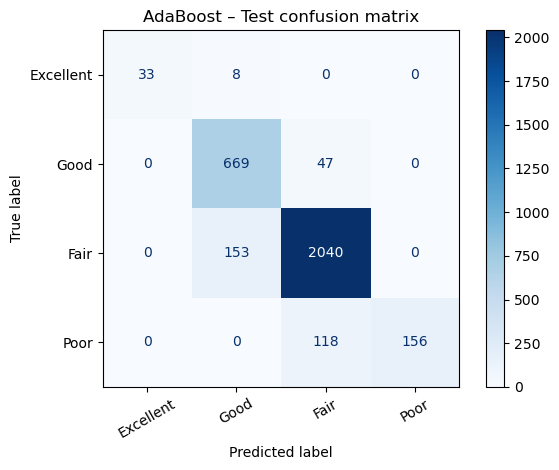

,Model,Split,Accuracy,Macro F1,Weighted F1
0,Random Forest,Test,0.984801,0.965786,0.984631
1,AdaBoost,Test,0.898883,0.852657,0.896241


In [11]:
rf_test_result = evaluate_model(random_forest, X_test, y_test, "Random Forest", "Test")
ada_test_result = evaluate_model(ada_boost, X_test, y_test, "AdaBoost", "Test")

test_results = pd.DataFrame([rf_test_result, ada_test_result])
test_results


In [12]:
os.makedirs("saved_models", exist_ok=True)
joblib.dump(random_forest, "saved_models/codd_random_forest.joblib")
joblib.dump(ada_boost, "saved_models/codd_adaboost.joblib")
print("Saved both pipelines in the saved_models/ folder.")


Saved both pipelines in the saved_models/ folder.
